In [62]:
from pathlib import Path
import pandas as pd
from pydeseq2.dds import DeseqDataSet
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [63]:
# The data available is here :
DATA_DIR = Path.cwd().parent / "data"

## Glioma interpretation table

In [64]:
glioma_class = pd.read_csv(DATA_DIR / "glioma-classification-and-mutations.csv")

In [65]:
glioma_class.head()

,patient,tcga_project,idh_status,codeletion_1p19q_status,historical_histology,historical_grade,historical_label_status,who_cns5_entity,who_cns5_grade,who_cns5_assignment_status,...,mutation_profile_present,atrx_used_in_who_assignment,tp53_status,tp53_driver_evidence,tp53_driver_variant_count,tp53_other_variant_count,atrx_status,atrx_driver_evidence,atrx_driver_variant_count,atrx_other_variant_count
0,TCGA-06-0125,GBM,wildtype,not_codeleted,glioblastoma,G4,historical_comparator,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,no_reported_variant,NaN,0,0,no_reported_variant,NaN,0,0
1,TCGA-06-0190,GBM,wildtype,not_codeleted,glioblastoma,G4,historical_comparator,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,driver_supported,two_concordant_tp53_function_assays,1,0,no_reported_variant,NaN,0,0
2,TCGA-06-0210,GBM,wildtype,not_codeleted,glioblastoma,G4,historical_comparator,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,driver_supported,two_concordant_tp53_function_assays,1,0,no_reported_variant,NaN,0,0
3,TCGA-06-0211,GBM,wildtype,not_codeleted,glioblastoma,G4,historical_comparator,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,no_reported_variant,NaN,0,0,no_reported_variant,NaN,0,0
4,TCGA-06-1804,GBM,wildtype,not_codeleted,glioblastoma,G4,source_conflict,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,no_reported_variant,NaN,0,0,no_reported_variant,NaN,0,0


## TCGA-LGG + TCGA-GBM

In [66]:
tcga_gbm = pd.read_csv(DATA_DIR / "tcga_gbm_wsi_ids.txt", header=None, names=["tcga_gbm"], dtype="string")

tcga_paad = pd.read_csv(DATA_DIR / "tcga_paad_wsi_ids.txt", header=None, names=["tcga_paad"], dtype="string")

In [67]:
tcga_gbm.head()

,tcga_gbm
0,TCGA-02-0025-01Z-00-DX1.bea1009d-61ab-48dc-a6a...
1,TCGA-02-0026-01Z-00-DX1.d8f3085f-e418-47da-86b...
2,TCGA-02-0010-01Z-00-DX1.b53f8c4e-6e10-4684-b7f...
3,TCGA-RR-A6KB-01Z-00-DX1.90E22C0F-CA68-4EEB-BB1...
4,TCGA-RR-A6KC-01Z-00-DX1.1D8F656F-9A5D-4143-847...


## Clinical records and sample QC

In [68]:
sample_QC = pd.read_csv(DATA_DIR / "merged_sample_quality_annotations.tsv", sep='\t')


In [69]:
sample_QC.head()

,patient_barcode,aliquot_barcode,cancer type,platform,patient_annotation,sample_annotation,aliquot_annotation,aliquot_annotation_updated,AWG_excluded_because_of_pathology,AWG_pathology_exclusion_reason,Reviewed_by_EPC,Do_not_use
0,TCGA-01-0628,TCGA-01-0628-11A-01D-0356-01,OV,Genome_Wide_SNP_6,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False
1,TCGA-01-0628,TCGA-01-0628-11A-01D-0383-05,OV,HumanMethylation27,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False
2,TCGA-01-0630,TCGA-01-0630-11A-01D-0356-01,OV,Genome_Wide_SNP_6,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False
3,TCGA-01-0630,TCGA-01-0630-11A-01D-0383-05,OV,HumanMethylation27,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False
4,TCGA-01-0631,TCGA-01-0631-11A-01D-0356-01,OV,Genome_Wide_SNP_6,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False


In [70]:
clinical_records = pd.read_csv(DATA_DIR / "clinical_PANCAN_patient_with_followup.tsv", sep='\t', encoding='Latin1')

/tmp/ipykernel_1657/3030050661.py:1: DtypeWarning: Columns (8: days_to_initial_pathologic_diagnosis, 9: age_at_initial_pathologic_diagnosis, 27: year_of_initial_pathologic_diagnosis, 42: postoperative_rx_tx, 44: lymph_node_examined_count, 45: primary_lymph_node_presentation_assessment, 46: initial_pathologic_diagnosis_method, 47: number_of_lymphnodes_positive_by_he, 48: eastern_cancer_oncology_group, 49: anatomic_neoplasm_subdivision, 50: residual_tumor, 51: histological_type_other, 52: init_pathology_dx_method_other, 53: karnofsky_performance_score, 55: height, 56: weight, 57: history_of_radiation_metastatic_site, 58: days_to_patient_progression_free, 59: days_to_first_response, 60: days_to_first_partial_response, 61: days_to_first_complete_response, 62: days_to_tumor_progression, 63: er_estimated_duration_response, 64: er_disease_extent_prior_er_treatment, 65: er_solid_tumor_response_documented_type, 66: er_solid_tumor_response_documented_type_other, 67: er_response_type, 68: history

In [71]:
clinical_records.head()

,bcr_patient_uuid,bcr_patient_barcode,acronym,gender,vital_status,days_to_birth,days_to_death,days_to_last_followup,days_to_initial_pathologic_diagnosis,age_at_initial_pathologic_diagnosis,...,total_bilirubin_upper_limit,platelet_result_count,fibrosis_ishak_score,fetoprotein_outcome_value,fetoprotein_outcome_upper_limit,fetoprotein_outcome_lower_limit,inter_norm_ratio_lower_limit,family_cancer_type_txt,bilirubin_upper_limit,days_to_last_known_alive
0,B3164F7B-C826-4E08-9EE6-8FF96D29B913,TCGA-OR-A5J1,ACC,MALE,Dead,-21496,1355.0,[Not Available],0,58,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8E7C2E31-D085-4B75-A970-162526DD07A0,TCGA-OR-A5J2,ACC,FEMALE,Dead,-16090,1677,[Not Available],0,44,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DFD687BC-6E69-42F7-AF94-D17FC150D1A1,TCGA-OR-A5J3,ACC,FEMALE,Alive,-8624,[Not Applicable],2091.0,0,23,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5F3E2974-F1DF-47A2-8A8A-29BB525EEEF6,TCGA-OR-A5J4,ACC,FEMALE,Dead,-8451,423,[Not Available],0,23,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,802DBD0D-EF07-4C91-AB8D-1DD39532E947,TCGA-OR-A5J5,ACC,MALE,Dead,-11171,365,[Not Available],0,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Make a patient inventory for glioma. Start with the clinical and sample-quality tables. Match primary tumour samples from LGG and GBM to the RNA, methylation and slide files by TCGA patient barcode. Count unique patients with each assay, with both molecular assays and with all three inputs. Document exclusions and how you handle multiple samples or slides from one patient.

In [72]:
metadata_LGG = sample_QC[sample_QC["cancer type"] == 'LGG']
metadata_GBM = sample_QC[sample_QC["cancer type"] == 'GBM']

metadata_LGG_GBM = pd.concat([metadata_LGG, metadata_GBM], axis=0, ignore_index=False, join="outer")
metadata_LGG_GBM.columns

Index(['patient_barcode', 'aliquot_barcode', 'cancer type', 'platform',
       'patient_annotation', 'sample_annotation', 'aliquot_annotation',
       'aliquot_annotation_updated', 'AWG_excluded_because_of_pathology',
       'AWG_pathology_exclusion_reason', 'Reviewed_by_EPC', 'Do_not_use'],
      dtype='str')

## RNAseq Preprocessing

In [73]:
counts_path = DATA_DIR / "EBPlusPlusAdjustPANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv"
expr_count = pd.read_csv(counts_path,index_col = 0, delimiter = "\t", na_values = "NaN")



In [74]:


expr_count = expr_count.fillna(0) # Remplace missing values µby 0
expr_count = expr_count.astype("int32")
counts_df = expr_count.T # Transpose to get a matrix samples x genes
# counts_df.set_index('sample', inplace=True) # Set the sample column as index


In [76]:
print(counts_df.index)

Index(['TCGA-02-0047-01A-01R-1849-01', 'TCGA-02-0055-01A-01R-1849-01',
       'TCGA-02-2483-01A-01R-1849-01', 'TCGA-02-2485-01A-01R-1849-01',
       'TCGA-02-2486-01A-01R-1849-01', 'TCGA-06-0125-01A-01R-1849-01',
       'TCGA-06-0125-02A-11R-2005-01', 'TCGA-06-0129-01A-01R-1849-01',
       'TCGA-06-0130-01A-01R-1849-01', 'TCGA-06-0132-01A-02R-1849-01',
       ...
       'TCGA-VW-A8FI-01A-11R-A36H-07', 'TCGA-W9-A837-01A-11R-A36H-07',
       'TCGA-WH-A86K-01A-11R-A36H-07', 'TCGA-WY-A858-01A-11R-A36H-07',
       'TCGA-WY-A859-01A-12R-A36H-07', 'TCGA-WY-A85A-01A-21R-A36H-07',
       'TCGA-WY-A85B-01A-11R-A36H-07', 'TCGA-WY-A85C-01A-11R-A36H-07',
       'TCGA-WY-A85D-01A-11R-A36H-07', 'TCGA-WY-A85E-01A-11R-A36H-07'],
      dtype='str', length=708)


In [ ]:
#Find common samples
common_samples = (counts_df.index).intersection(metadata_LGG_GBM['aliquot_barcode'])

#Filter and order the two tables
counts_df = counts_df.loc[common_samples]
metadata_LGG_GBM = metadata_LGG_GBM.loc[common_samples]
# counts_GBM = counts_df.loc[GBM_samples]
# counts_LGG = counts_df.loc[LGG_samples]


In [ ]:
print(counts_df.index,metadata_LGG_GBM['aliquot_barcode'], common_samples)

metadata_LGG_GBM.shape

Index(['TCGA-02-0047-01A-01R-1849-01', 'TCGA-02-0055-01A-01R-1849-01',
       'TCGA-02-2483-01A-01R-1849-01', 'TCGA-02-2485-01A-01R-1849-01',
       'TCGA-02-2486-01A-01R-1849-01', 'TCGA-06-0125-01A-01R-1849-01',
       'TCGA-06-0125-02A-11R-2005-01', 'TCGA-06-0129-01A-01R-1849-01',
       'TCGA-06-0130-01A-01R-1849-01', 'TCGA-06-0132-01A-02R-1849-01',
       ...
       'TCGA-VW-A8FI-01A-11R-A36H-07', 'TCGA-W9-A837-01A-11R-A36H-07',
       'TCGA-WH-A86K-01A-11R-A36H-07', 'TCGA-WY-A858-01A-11R-A36H-07',
       'TCGA-WY-A859-01A-12R-A36H-07', 'TCGA-WY-A85A-01A-21R-A36H-07',
       'TCGA-WY-A85B-01A-11R-A36H-07', 'TCGA-WY-A85C-01A-11R-A36H-07',
       'TCGA-WY-A85D-01A-11R-A36H-07', 'TCGA-WY-A85E-01A-11R-A36H-07'],
      dtype='str', length=708) Index(['TCGA-02-0047-01A-01R-1849-01', 'TCGA-02-0055-01A-01R-1849-01',
       'TCGA-02-2483-01A-01R-1849-01', 'TCGA-02-2485-01A-01R-1849-01',
       'TCGA-02-2486-01A-01R-1849-01', 'TCGA-06-0125-01A-01R-1849-01',
       'TCGA-06-0125-02A-11R-2005-

(708, 11)

In [90]:
deseqexpr = DeseqDataSet(counts=counts_df,
    metadata=metadata_LGG_GBM,
    design="~ 1"
)
deseqexpr

AnnData object with n_obs × n_vars = 708 × 20531
    obs: 'patient_barcode', 'cancer type', 'platform', 'patient_annotation', 'sample_annotation', 'aliquot_annotation', 'aliquot_annotation_updated', 'AWG_excluded_because_of_pathology', 'AWG_pathology_exclusion_reason', 'Reviewed_by_EPC', 'Do_not_use'
    obsm: 'design_matrix'
    layers: None (.X)

In [ ]:
#Normalize the counts using DESeq2
deseqexpr.vst(use_design=False, fit_type="parametric")

vst_df = pd.DataFrame(
    deseqexpr.layers["vst_counts"],
    index=counts_df.index,
    columns=counts_df.columns,
).T

,TCGA-02-0047-01A-01R-1849-01,TCGA-02-0055-01A-01R-1849-01,TCGA-02-2483-01A-01R-1849-01,TCGA-02-2485-01A-01R-1849-01,TCGA-02-2486-01A-01R-1849-01,TCGA-06-0125-01A-01R-1849-01,TCGA-06-0125-02A-11R-2005-01,TCGA-06-0129-01A-01R-1849-01,TCGA-06-0130-01A-01R-1849-01,TCGA-06-0132-01A-02R-1849-01,...,TCGA-VW-A8FI-01A-11R-A36H-07,TCGA-W9-A837-01A-11R-A36H-07,TCGA-WH-A86K-01A-11R-A36H-07,TCGA-WY-A858-01A-11R-A36H-07,TCGA-WY-A859-01A-12R-A36H-07,TCGA-WY-A85A-01A-21R-A36H-07,TCGA-WY-A85B-01A-11R-A36H-07,TCGA-WY-A85C-01A-11R-A36H-07,TCGA-WY-A85D-01A-11R-A36H-07,TCGA-WY-A85E-01A-11R-A36H-07
gene_id,,,,,,,,,,,,,,,,,,,,,
?|100130426,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,...,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819
?|100133144,4.571656,3.942819,4.449023,5.283064,4.741110,4.999184,4.577332,5.535175,3.942819,4.459993,...,5.454902,5.185959,5.070220,4.889643,4.584954,4.750405,4.940207,5.094996,4.746240,5.003401
?|100134869,4.825360,5.293414,5.199876,5.240493,4.658612,5.105239,4.577332,5.318104,4.448084,4.574563,...,5.525669,5.746060,5.264296,5.344345,5.094100,5.349965,5.442283,5.394189,4.951583,4.882662
?|10357,6.344740,5.820698,6.415640,6.847719,6.458741,6.276298,6.100635,6.643162,5.911078,6.047250,...,7.255962,7.090421,7.859559,7.714776,7.306630,7.246578,7.288938,7.148727,7.063002,7.387586
?|10431,9.825142,9.790278,10.241664,8.897505,9.123479,8.660565,8.821572,9.310363,9.584804,9.528522,...,9.178478,9.323153,9.212983,9.599493,9.867049,9.412130,9.373355,9.030410,9.492742,9.556203
?|136542,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,...,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819
?|155060,8.018971,7.539062,7.307194,8.736282,8.212212,9.544677,7.421686,9.513692,9.124597,6.788063,...,10.174881,8.619912,9.365619,9.723538,8.923496,9.140821,9.260891,9.674748,9.676587,10.209078
?|26823,3.942819,3.942819,3.942819,4.300530,3.942819,4.301931,3.942819,4.649703,3.942819,3.942819,...,4.304861,4.463348,4.307504,4.306180,3.942819,4.307743,4.448905,4.556016,3.942819,4.303421
?|280660,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,...,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819,3.942819


In [92]:
# only keep genes with non-zero variance in both LGG and GBM samples
cohort_map = metadata_LGG_GBM.loc[common_samples, "cancer type"]
lgg_cols = cohort_map.index[cohort_map == "LGG"].tolist()
gbm_cols = cohort_map.index[cohort_map == "GBM"].tolist()
assert not set(lgg_cols) & set(gbm_cols)

var_lgg = vst_df[lgg_cols].var(axis=1, ddof=1)
var_gbm = vst_df[gbm_cols].var(axis=1, ddof=1)

valid_genes = var_lgg.index[(var_lgg > 0) & (var_gbm > 0)]
var_lgg = var_lgg.loc[valid_genes]
var_gbm = var_gbm.loc[valid_genes]

# Average intra cohort variance for each gene
within_cohort_var = 0.5 * (var_lgg + var_gbm)

# Top N genes
top_n = min(5000, len(within_cohort_var))
print(top_n, "gènes avec la plus forte variance intra-cohorte sélectionnés.")
top_genes = within_cohort_var.sort_values(ascending=False).head(top_n).index

# Filtered matrix with only the top N genes
vst_df_filtered = vst_df.loc[top_genes, lgg_cols + gbm_cols]
vst_df_filtered.head(10)

print(len(lgg_cols), len(gbm_cols))
print(len(set(lgg_cols) & set(gbm_cols)))


5000 gènes avec la plus forte variance intra-cohorte sélectionnés.
534 174
0


In [93]:
#Matrix for PCA : samples in rows, genes in columns:
pca_matrix = vst_df_filtered.T.copy()

#Run PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(pca_matrix)

pca_df = pd.DataFrame(
    coords,
    index=pca_matrix.index,  
    columns=["PC1", "PC2"],
)
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

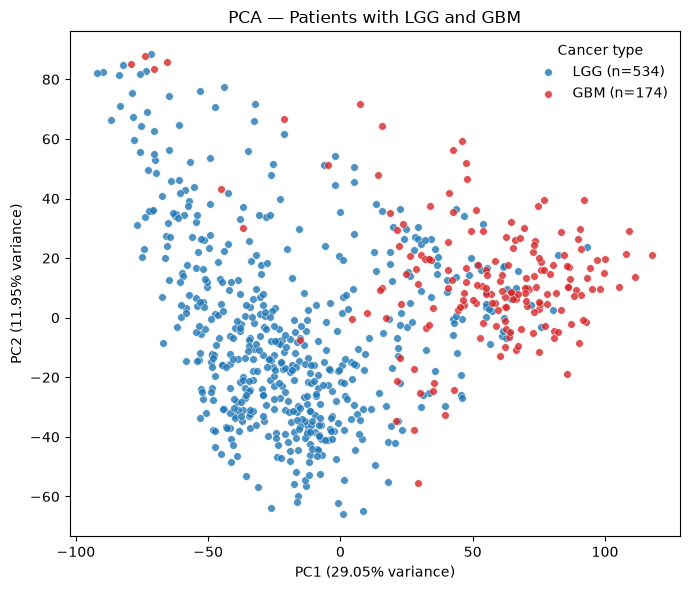

In [94]:
from matplotlib.lines import Line2D

#Add colours for each cohort
colours = {"LGG": "#1f77b4", "GBM": "#d62728"}  

cohort = pd.Series(
    ["LGG"] * len(lgg_cols) + ["GBM"] * len(gbm_cols),
    index=lgg_cols + gbm_cols,
)
pca_df["cancer_type"] = cohort.loc[pca_df.index].values

fig, ax = plt.subplots(figsize=(7, 6))
for name, color in colours.items():
    sub = pca_df[pca_df["cancer_type"] == name]
    ax.scatter(sub["PC1"], sub["PC2"], c=color, alpha=0.8,
               s=30, edgecolor="white", linewidth=0.4,
               label=f"{name} (n={len(sub)})")

ax.set_xlabel(f"PC1 ({var_pc1:.2f}% variance)")
ax.set_ylabel(f"PC2 ({var_pc2:.2f}% variance)")
ax.set_title("PCA — Patients with LGG and GBM")
ax.legend(title="Cancer type", frameon=False)
plt.tight_layout()
plt.savefig("pca_coloured.png", dpi=300)
plt.show()
plt.close(fig)

In [ ]:
# Save the figure and the PCA coordinates to CSV
# pca_df.to_csv("pca_coordinates_RNAseq.csv")